<a href="https://colab.research.google.com/github/hanane-boob/Cytokine-analysis/blob/main/Tp2_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
rng = np.random.default_rng(seed=2025)
plt.rcParams["figure.figsize"] = (7, 4)




In [ ]:
conc = np.array([0, 2, 4, 6, 8, 10]) # µg/mL
absorbance = 0.0512 * conc + 0.004 + rng.normal(0, 0.008, conc.size)
absorbance = absorbance.round(3)
pd.DataFrame({"concentration (µg/mL)": conc, "absorbance": absorbance})

,concentration (µg/mL),absorbance
0,0,-0.002
1,2,0.109
2,4,0.214
3,6,0.314
4,8,0.412
5,10,0.521


In [ ]:
# 1) Droite de régression
pente, ordonnee = np.polyfit(conc, absorbance, 1)

# 2) Coefficient de détermination R²
A_calc = pente * conc + ordonnee
ss_res = np.sum((absorbance - A_calc) ** 2)
ss_tot = np.sum((absorbance - np.mean(absorbance)) ** 2)
R2 = 1 - ss_res / ss_tot

# 3) Affichage
print(f"pente = {pente:.4f} | ordonnée = {ordonnee:.4f} | R² = {R2:.4f}")

pente = 0.0518 | ordonnée = 0.0025 | R² = 0.9996


Dans la cuvette : 5.94 µg/mL
Solution mère : 29.7 µg/mL


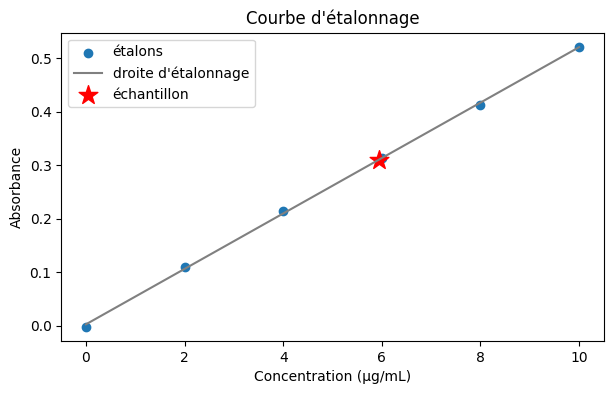

In [ ]:
A_inconnu = 0.310
dilution = 5

C_cuvette = (A_inconnu - ordonnee) / pente
C_mere = C_cuvette * dilution

print(f"Dans la cuvette : {C_cuvette:.2f} µg/mL")
print(f"Solution mère : {C_mere:.1f} µg/mL")

# Graphique
plt.scatter(conc, absorbance, label="étalons")
plt.plot(conc, A_calc, color="gray", label="droite d'étalonnage")

plt.scatter(C_cuvette, A_inconnu, marker="*", s=200,
            color="red", label="échantillon")

plt.title("Courbe d'étalonnage")
plt.xlabel("Concentration (µg/mL)")
plt.ylabel("Absorbance")
plt.legend()
plt.show()

In [ ]:
def michaelis(S, Vmax, Km):
    return Vmax * S / (Km + S)

S = np.array([0.5, 1, 2, 5, 10, 20, 50, 100])

I = 10

v_sans = (michaelis(S, 120, 8) * rng.normal(1, 0.04, S.size)).round(1)

v_avec = (michaelis(S, 120, 8 * (1 + I / 5)) * rng.normal(1, 0.04, S.size)).round(1)

pd.DataFrame({
    "S (mM)": S,
    "v sans inhibiteur": v_sans,
    "v avec inhibiteur": v_avec
})

,S (mM),v sans inhibiteur,v avec inhibiteur
0,0.5,7.2,2.3
1,1.0,13.7,4.7
2,2.0,22.4,8.7
3,5.0,45.4,20.8
4,10.0,64.9,37.9
5,20.0,95.8,52.6
6,50.0,100.7,83.6
7,100.0,116.7,99.8


In [ ]:
# Sans inhibiteur
param_sans, _ = curve_fit(michaelis, S, v_sans, p0=[100, 5])
Vmax_sans, Km_sans = param_sans

# Avec inhibiteur
param_avec, _ = curve_fit(michaelis, S, v_avec, p0=[100, 5])
Vmax_avec, Km_avec = param_avec

pd.DataFrame(
    {"Vmax": [Vmax_sans, Vmax_avec],
     "Km (mM)": [Km_sans, Km_avec]},
    index=["sans inhibiteur", "avec inhibiteur"]
).round(1)

,Vmax,Km (mM)
sans inhibiteur,124.8,8.5
avec inhibiteur,125.0,25.3


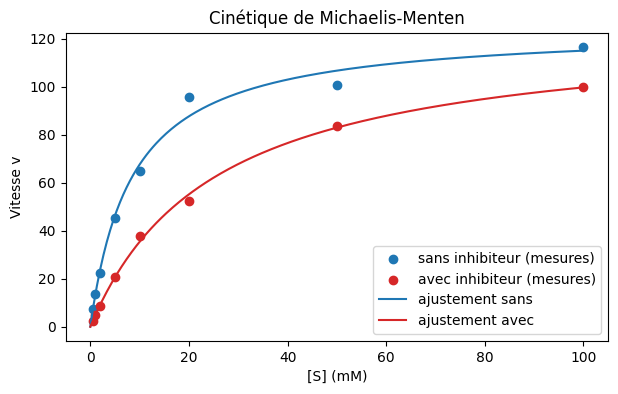

In [ ]:
S_fin = np.linspace(0, 100, 300)

plt.scatter(S, v_sans, color="tab:blue", label="sans inhibiteur (mesures)")
plt.scatter(S, v_avec, color="tab:red", label="avec inhibiteur (mesures)")

plt.plot(S_fin, michaelis(S_fin, Vmax_sans, Km_sans), color="tab:blue",
         label="ajustement sans")

plt.plot(S_fin, michaelis(S_fin, Vmax_avec, Km_avec), color="tab:red",
         label="ajustement avec")

plt.title("Cinétique de Michaelis-Menten")
plt.xlabel("[S] (mM)")
plt.ylabel("Vitesse v")
plt.legend()
plt.show()

In [ ]:
Ki = I / (Km_avec / Km_sans - 1)
print(f"Ki = {Ki:.1f} mM")

Ki = 5.0 mM


In [ ]:
def hill(logC, Emin, Emax, logEC50, n):
    return Emin + (Emax - Emin) / (1 + 10 ** ((logEC50 - logC) * n))

logC = np.arange(-9, -3.5, 0.5)
effet_A = (hill(logC, 2, 98, -7.0, 1.0) + rng.normal(0, 3, logC.size)).round(1)
effet_B = (hill(logC, 2, 98, -6.3, 1.0) + rng.normal(0, 3, logC.size)).round(1)

pd.DataFrame({"logC": logC, "effet A (%)": effet_A, "effet B (%)": effet_B})

,logC,effet A (%),effet B (%)
0,-9.0,4.9,-0.6
1,-8.5,4.3,4.3
2,-8.0,10.3,5.3
3,-7.5,25.5,10.9
4,-7.0,50.6,11.3
5,-6.5,75.4,41.0
6,-6.0,91.6,58.7
7,-5.5,94.7,84.7
8,-5.0,98.7,86.0
9,-4.5,98.6,100.5


In [ ]:
# Composé A
pA, _ = curve_fit(hill, logC, effet_A, p0=[0, 100, -7, 1])
EC50_A = 10 ** pA[2] * 1e9  # en nM

# Composé B : même chose avec la deuxième série d'effets
pB, _ = curve_fit(hill, logC, effet_B, p0=[0, 100, -7, 1])
# en nM (indice : le logEC50 est le 3e paramètre, pB[2])
EC50_B = 10 ** pB[2] * 1e9

tableau = pd.DataFrame({"Emax": [pA[1], pB[1]], "pEC50": [-pA[2], -pB[2]],
                        "EC50 (nM)": [EC50_A, EC50_B], "pente de Hill": [pA[3], pB[3]]},
                       index=["Composé A", "Composé B"])

tableau.round(2)

,Emax,pEC50,EC50 (nM),pente de Hill
Composé A,97.57,7.00,98.90,1.07
Composé B,97.47,6.24,581.16,0.94


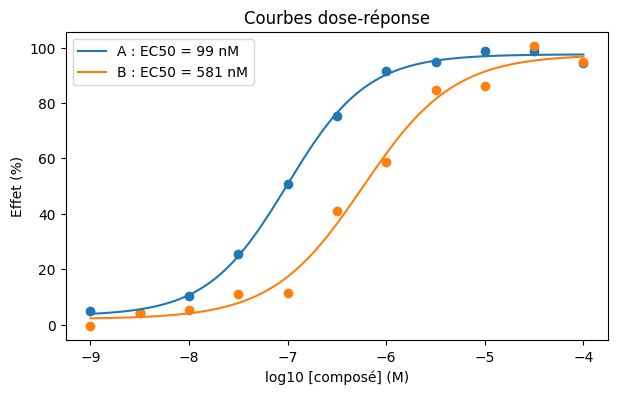

In [ ]:
x = np.linspace(-9, -4, 200)

plt.scatter(logC, effet_A, color="tab:blue")
plt.scatter(logC, effet_B, color="tab:orange")

plt.plot(x, hill(x, *pA), color="tab:blue",
         label=f"A : EC50 = {EC50_A:.0f} nM")

plt.plot(x, hill(x, *pB), color="tab:orange",
         label=f"B : EC50 = {EC50_B:.0f} nM")

plt.title("Courbes dose-réponse")
plt.xlabel("log10 [composé] (M)")
plt.ylabel("Effet (%)")
plt.legend()
plt.show()

In [ ]:
dose = 500
t = np.array([0.25, 0.5, 1, 2, 4, 6, 8, 12, 24])
conc_pl = (12.5 * np.exp(-0.173 * t) + rng.normal(0, 0.05, t.size)).round(2)

pk = pd.DataFrame({"temps (h)": t, "concentration (mg/L)": conc_pl})
pk

,temps (h),concentration (mg/L)
0,0.25,12.08
1,0.50,11.47
2,1.00,10.56
3,2.00,8.87
4,4.00,6.35
5,6.00,4.43
6,8.00,3.08
7,12.00,1.51
8,24.00,0.15


In [ ]:
# logarithme népérien des concentrations
ln_conc = np.log(conc_pl)

# régression de ln(C) en fonction de t
pente_pk, ordonnee_pk = np.polyfit(t, ln_conc, 1)

k = -pente_pk
C0 = np.exp(ordonnee_pk)                 # concentration initiale (mg/L)
t_demi = np.log(2) / k                  # demi-vie (h)
Vd = dose / C0                          # volume de distribution (L)

print(f"k = {k:.3f} 1/h | C0 = {C0:.1f} mg/L | t1/2 = {t_demi:.1f} h | Vd = {Vd:.0f} L")

k = 0.184 1/h | C0 = 13.0 mg/L | t1/2 = 3.8 h | Vd = 39 L


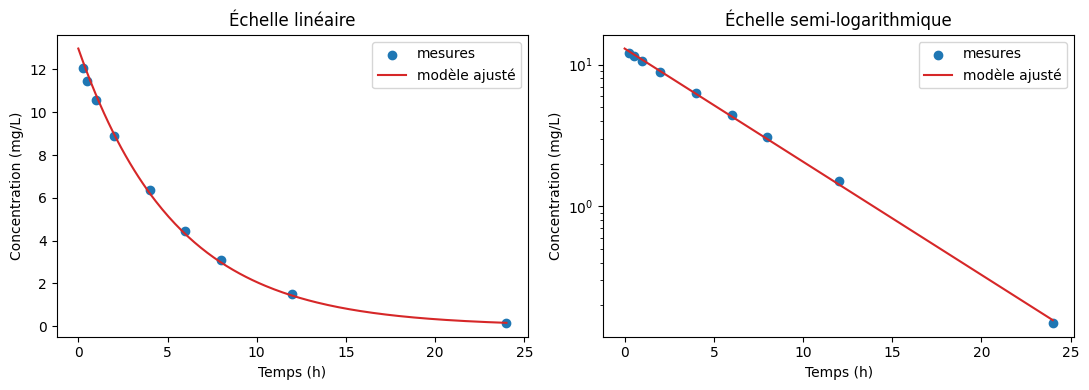

In [ ]:
t_fin = np.linspace(0, 24, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for a, titre in zip(ax, ["Échelle linéaire", "Échelle semi-logarithmique"]):
    a.scatter(t, conc_pl, label="mesures")
    a.plot(t_fin, C0 * np.exp(-k * t_fin), color="tab:red", label="modèle ajusté")
    a.set_title(titre)
    a.set_xlabel("Temps (h)")
    a.set_ylabel("Concentration (mg/L)")
    a.legend()

ax[1].set_yscale("log")
plt.tight_layout()
plt.show()

In [ ]:
temps_97 = 5 * t_demi

print(f"Temps pour éliminer 97 % de la dose : environ {temps_97:.0f} h")

Temps pour éliminer 97 % de la dose : environ 19 h


In [ ]:
# VOTRE CODE ICI (facultatif)